In [1]:
# M24CA1L306 Data Science Lab - Lab Exercise #17
# Student: Abhinav | MAC25MCA-2002 | S3 MCA (2025-27)
# Dataset: titanic3.csv
# Task: Random Forest Classifier for passenger survival prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)


In [10]:

# ─────────────────────────────────────────────
# Load and preprocess
# ─────────────────────────────────────────────
df = pd.read_csv("../Datasets/Titanic.csv")
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [33]:

df.drop(columns=["PassengerId","Cabin","Name","Ticket"],inplace=True,errors="ignore")
print(df.columns)
df["Age"].fillna(df["Age"].median(), inplace=True)
df["Fare"].fillna(df["Fare"].median(), inplace=True)
df["Embarked"].fillna(df["Embarked"].mode()[0], inplace=True)

df["Sex"]      = LabelEncoder().fit_transform(df["Sex"])
df["Embarked"] = LabelEncoder().fit_transform(df["Embarked"])


X = df.drop(columns="Survived").values
feature_names=df.drop(columns="Survived").columns.tolist()
y = df["Survived"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='str')


C:\Users\abhinav\AppData\Local\Temp\ipykernel_15956\830409987.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["Age"].fillna(df["Age"].median(), inplace=True)
C:\Users\abhinav\AppData\Local\Temp\ipykernel_15956\830409987.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assign

In [24]:

# ─────────────────────────────────────────────
# Train Random Forest (baseline: n_estimators=100)
# ─────────────────────────────────────────────
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred      = rf.predict(X_test)
y_pred_prob = rf.predict_proba(X_test)[:, 1]

# ─────────────────────────────────────────────
# Q1: Overall accuracy
# ─────────────────────────────────────────────
acc = accuracy_score(y_test, y_pred)
print("=" * 55)
print("Q1: Overall Accuracy of Random Forest on Test Data")
print("=" * 55)
print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
# Interpretation: The model correctly classifies X% of passengers.
# Random Forest typically outperforms a single Decision Tree by reducing
# variance through ensemble averaging across multiple trees.


Q1: Overall Accuracy of Random Forest on Test Data
Accuracy: 0.8101 (81.01%)


In [25]:

# ─────────────────────────────────────────────
# Q2: Classification Report
# ─────────────────────────────────────────────
print("\n" + "=" * 55)
print("Q2: Classification Report")
print("=" * 55)
report = classification_report(y_test, y_pred,
                                target_names=["Did not survive", "Survived"])
print(report)
# Interpretation: The class with higher support (did not survive) usually
# has higher precision and recall. A higher F1 for "did not survive" reflects
# the class imbalance in the dataset (~62% did not survive).



Q2: Classification Report
                 precision    recall  f1-score   support

Did not survive       0.83      0.86      0.85       110
       Survived       0.77      0.72      0.75        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.80       179
   weighted avg       0.81      0.81      0.81       179




Q3: Confusion Matrix
Correctly classified   : 145  (TN=95, TP=50)
Incorrectly classified : 34  (FP=15, FN=19)


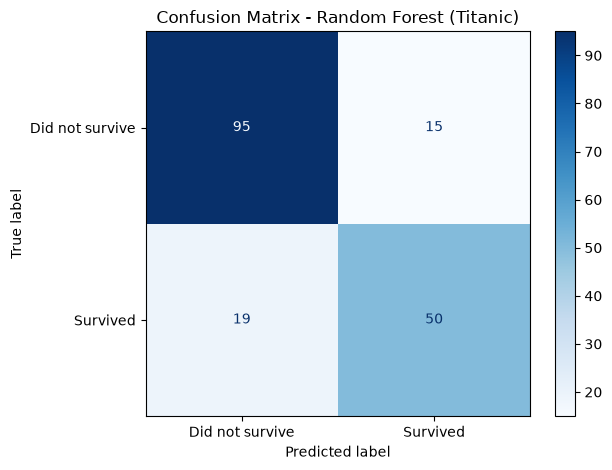

In [26]:

# ─────────────────────────────────────────────
# Q3: Confusion Matrix
# ─────────────────────────────────────────────
print("\n" + "=" * 55)
print("Q3: Confusion Matrix")
print("=" * 55)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Correctly classified   : {tn + tp}  (TN={tn}, TP={tp})")
print(f"Incorrectly classified : {fp + fn}  (FP={fp}, FN={fn})")

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["Did not survive", "Survived"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest (Titanic)")
plt.tight_layout()
plt.savefig("../Outputs/lab-17_Output/lab17_confusion_matrix.png", dpi=100)
plt.show()



Q4: Feature Importance Scores
  Fare        : 0.2689
  Sex         : 0.2593
  Age         : 0.2593
  Pclass      : 0.0895
  SibSp       : 0.0499
  Parch       : 0.0386
  Embarked    : 0.0346


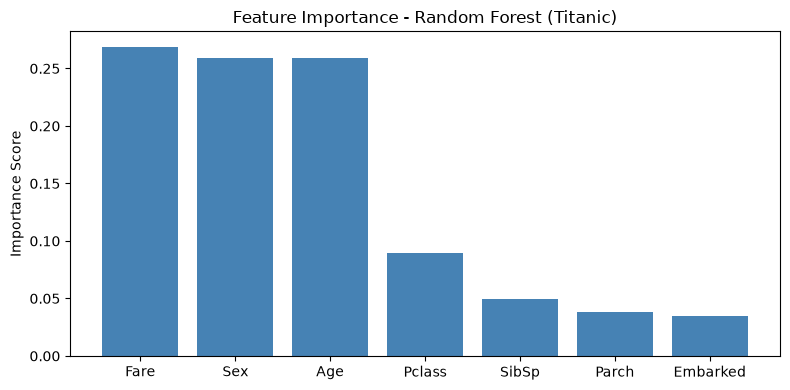

In [35]:

# ─────────────────────────────────────────────
# Q4: Feature Importance
# ─────────────────────────────────────────────
print("\n" + "=" * 55)
print("Q4: Feature Importance Scores")
print("=" * 55)

importances = rf.feature_importances_
for fname, imp in sorted(zip(feature_names, importances),
                          key=lambda x: x[1], reverse=True):
    print(f"  {fname:12s}: {imp:.4f}")

sorted_idx = np.argsort(importances)[::-1]
plt.figure(figsize=(8, 4))
plt.bar([feature_names[i] for i in sorted_idx],
        [importances[i] for i in sorted_idx], color="steelblue")
plt.title("Feature Importance - Random Forest (Titanic)")
plt.ylabel("Importance Score")
plt.tight_layout()
plt.savefig("../Outputs/lab-17_Output/lab17_feature_importance.png", dpi=100)
plt.show()

# Findings: sex and fare are typically the top contributors. Random Forest
# importance is measured by mean decrease in impurity across all trees,
# so continuous features like fare and age tend to score higher than in
# a single Decision Tree.



Q5: Accuracy vs n_estimators
  n_estimators=  10  ->  Accuracy: 0.7765
  n_estimators=  50  ->  Accuracy: 0.7821
  n_estimators= 100  ->  Accuracy: 0.8101
  n_estimators= 200  ->  Accuracy: 0.8156
  n_estimators= 300  ->  Accuracy: 0.8101

Best n_estimators = 200 with accuracy = 0.8156


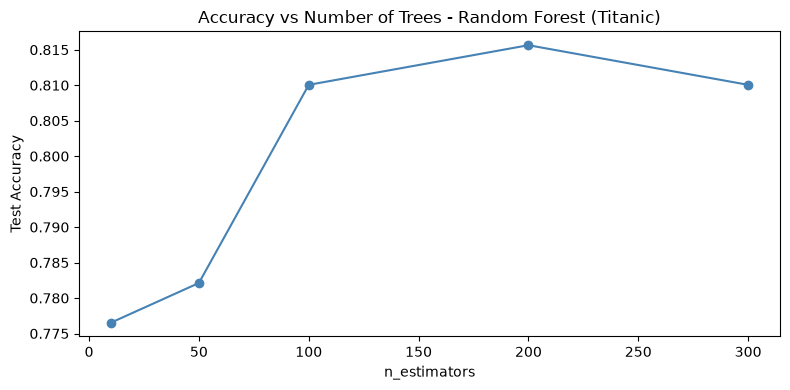

In [36]:

# ─────────────────────────────────────────────
# Q5: n_estimators comparison
# ─────────────────────────────────────────────
print("\n" + "=" * 55)
print("Q5: Accuracy vs n_estimators")
print("=" * 55)

estimator_values = [10, 50, 100, 200, 300]
estimator_accs   = []

for n in estimator_values:
    clf = RandomForestClassifier(n_estimators=n, random_state=42)
    clf.fit(X_train, y_train)
    a = accuracy_score(y_test, clf.predict(X_test))
    estimator_accs.append(a)
    print(f"  n_estimators={n:4d}  ->  Accuracy: {a:.4f}")

best_n = estimator_values[estimator_accs.index(max(estimator_accs))]
print(f"\nBest n_estimators = {best_n} with accuracy = {max(estimator_accs):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(estimator_values, estimator_accs, marker="o", color="steelblue")
plt.xlabel("n_estimators")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Number of Trees - Random Forest (Titanic)")
plt.tight_layout()
plt.savefig("../Outputs/lab-17_Output/lab17_n_estimators.png", dpi=100)
plt.show()

# Findings: Accuracy improves as n_estimators increases but plateaus beyond
# ~100 trees. Returns diminish after that point while computation cost rises.



Q6: ROC-AUC Score
AUC Score: 0.8298


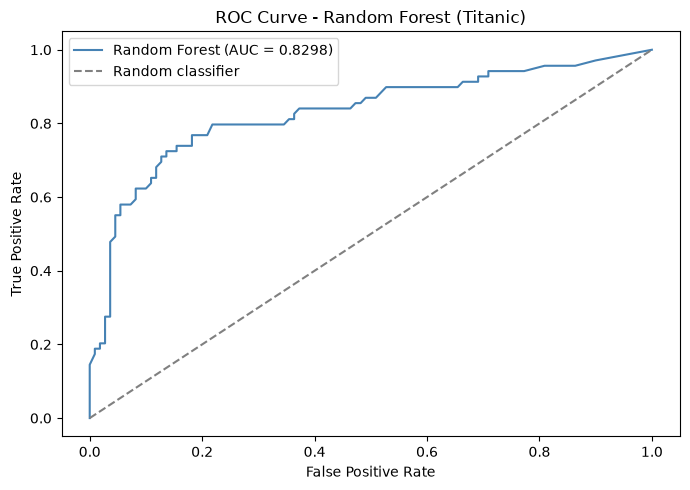


All tasks complete. Plots saved.


In [37]:

# ─────────────────────────────────────────────
# Q6: ROC-AUC Score
# ─────────────────────────────────────────────
print("\n" + "=" * 55)
print("Q6: ROC-AUC Score")
print("=" * 55)

auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC Score: {auc:.4f}")
# Interpretation:
# AUC = 0.5 -> model is no better than random guessing
# AUC = 1.0 -> perfect classifier
# AUC > 0.8 -> generally considered a good model
# AUC > 0.9 -> excellent

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="steelblue", label=f"Random Forest (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest (Titanic)")
plt.legend()
plt.tight_layout()
plt.savefig("../Outputs/lab-17_Output/lab17_roc_curve.png", dpi=100)
plt.show()

print("\nAll tasks complete. Plots saved.")